In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.simplefilter('ignore')

In [2]:
df = pd.read_csv("agentic_reality.csv")
df.head()

,Project_ID,Industry,Agent_Type,Primary_Tool,Status,Failure_Reason,Human_in_the_Loop_Ratio,Tokens_per_Task,ROI_Score
0,AGP-0001,Insurance,Autonomous,LangGraph,Production,NaN,0.389,2094,2.51
1,AGP-0002,Retail,Assistant,CrewAI,Production,NaN,0.990,5993,3.78
2,AGP-0003,Energy,Multi-agent Swarm,AutoGPT 3.0,Pilot,Loop Error,0.475,9032,0.91
3,AGP-0004,Technology,Multi-agent Swarm,LangGraph,Pilot,Loop Error,0.372,8735,0.75
4,AGP-0005,Finance,Autonomous,LangGraph,Production,NaN,0.613,1645,2.58


In [3]:
df.shape

(2500, 9)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 9 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Project_ID               2500 non-null   object 
 1   Industry                 2500 non-null   object 
 2   Agent_Type               2500 non-null   object 
 3   Primary_Tool             2500 non-null   object 
 4   Status                   2500 non-null   object 
 5   Failure_Reason           2154 non-null   object 
 6   Human_in_the_Loop_Ratio  2500 non-null   float64
 7   Tokens_per_Task          2500 non-null   int64  
 8   ROI_Score                2500 non-null   float64
dtypes: float64(2), int64(1), object(6)
memory usage: 175.9+ KB


In [5]:
df.isnull().sum()

Project_ID                   0
Industry                     0
Agent_Type                   0
Primary_Tool                 0
Status                       0
Failure_Reason             346
Human_in_the_Loop_Ratio      0
Tokens_per_Task              0
ROI_Score                    0
dtype: int64

In [6]:
# Failure_Reason is usually blank for projects that didn't fail, so label it instead of using the mode
df['Failure_Reason'] = df['Failure_Reason'].fillna('None')

# Fill any other missing categoricals with mode, numerics with median
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].fillna(df[col].mode()[0])

for col in df.select_dtypes(include=np.number).columns:
    df[col] = df[col].fillna(df[col].median())

print(df.isnull().sum().sum(), "missing values left")

0 missing values left


In [7]:
df = df.drop_duplicates()
print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (2500, 9)


In [8]:
# Create a copy for clustering (Project_ID is just an identifier, so it's excluded)
num_cols = ['Human_in_the_Loop_Ratio', 'Tokens_per_Task', 'ROI_Score']
cat_cols = ['Industry', 'Agent_Type', 'Primary_Tool', 'Status', 'Failure_Reason']

X = df[num_cols + cat_cols].copy()

# One-hot encode categorical columns
X = pd.get_dummies(X, columns=cat_cols, drop_first=False, dtype=int)

In [9]:
print("Features used for clustering:")
print(X.columns)

print("\nMissing values:")
print(X.isnull().sum().sum())

print("\nData types:")
print(X.dtypes.value_counts())

Features used for clustering:
Index(['Human_in_the_Loop_Ratio', 'Tokens_per_Task', 'ROI_Score',
       'Industry_Energy', 'Industry_Finance', 'Industry_Government',
       'Industry_Healthcare', 'Industry_Insurance', 'Industry_Legal',
       'Industry_Manufacturing', 'Industry_Retail', 'Industry_Technology',
       'Industry_Telecom', 'Agent_Type_Assistant', 'Agent_Type_Autonomous',
       'Agent_Type_Multi-agent Swarm', 'Primary_Tool_AutoGPT 3.0',
       'Primary_Tool_CrewAI', 'Primary_Tool_LangGraph', 'Status_Abandoned',
       'Status_Pilot', 'Status_Production', 'Failure_Reason_Cost Overrun',
       'Failure_Reason_Loop Error', 'Failure_Reason_None',
       'Failure_Reason_Schema Drift', 'Failure_Reason_Security Violation'],
      dtype='object')

Missing values:
0

Data types:
int64      25
float64     2
Name: count, dtype: int64


In [10]:
X.describe()

,Human_in_the_Loop_Ratio,Tokens_per_Task,ROI_Score,Industry_Energy,Industry_Finance,Industry_Government,Industry_Healthcare,Industry_Insurance,Industry_Legal,Industry_Manufacturing,...,Primary_Tool_CrewAI,Primary_Tool_LangGraph,Status_Abandoned,Status_Pilot,Status_Production,Failure_Reason_Cost Overrun,Failure_Reason_Loop Error,Failure_Reason_None,Failure_Reason_Schema Drift,Failure_Reason_Security Violation
count,2500.000000,2500.000000,2500.000000,2500.000000,2500.00000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,...,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.0000,2500.000000,2500.000000,2500.000000
mean,0.484933,5148.214800,0.425728,0.062000,0.16400,0.079600,0.131600,0.076000,0.073600,0.086800,...,0.340400,0.423600,0.354800,0.506800,0.138400,0.230400,0.2852,0.138400,0.175600,0.170400
std,0.271753,2473.059822,1.272453,0.241204,0.37035,0.270727,0.338123,0.265051,0.261171,0.281598,...,0.473938,0.494227,0.478548,0.500054,0.345388,0.421173,0.4516,0.345388,0.380556,0.376059
min,0.010000,500.000000,-2.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0000,0.000000,0.000000,0.000000
25%,0.239750,3491.000000,-0.470000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0000,0.000000,0.000000,0.000000
50%,0.483000,4655.500000,0.160000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.0000,0.000000,0.000000,0.000000
75%,0.724000,6322.500000,1.060000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,...,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,1.0000,0.000000,0.000000,0.000000
max,0.990000,20155.000000,5.000000,1.000000,1.00000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.0000,1.000000,1.000000,1.000000


In [12]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled data shape:", X_scaled.shape)

Scaled data shape: (2500, 27)


In [13]:
# Use a sample for hierarchical clustering (2500 rows, so this uses everything)
sample_size = min(5000, len(X_scaled))

X_sample = X_scaled[:sample_size]

print("Sample shape:", X_sample.shape)

Sample shape: (2500, 27)


In [14]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

silhouette_scores = []

for k in range(2, 7):

    hierarchical = AgglomerativeClustering(
        n_clusters=k,
        linkage='ward'
    )

    labels = hierarchical.fit_predict(X_sample)

    score = silhouette_score(X_sample, labels)

    silhouette_scores.append(score)

    print("K =", k, "Silhouette Score =", round(score, 4))

K = 2 Silhouette Score = 0.1689
K = 3 Silhouette Score = 0.0677
K = 4 Silhouette Score = 0.0826
K = 5 Silhouette Score = 0.103
K = 6 Silhouette Score = 0.1231


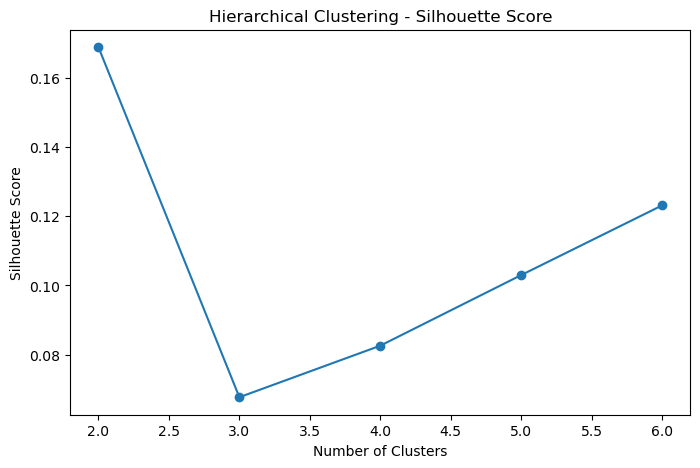

In [15]:
plt.figure(figsize=(8, 5))

plt.plot(range(2, 7), silhouette_scores, marker='o')

plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.title("Hierarchical Clustering - Silhouette Score")

plt.show()

In [16]:
best_k = range(2, 7)[np.argmax(silhouette_scores)]

print("Best number of clusters:", best_k)

Best number of clusters: 2


In [17]:
hierarchical = AgglomerativeClustering(
    n_clusters=best_k,
    linkage='ward'
)

hierarchical_labels = hierarchical.fit_predict(X_sample)

In [18]:
hierarchical_score = silhouette_score(X_sample, hierarchical_labels)

print("Hierarchical Clustering completed!")
print("Silhouette Score:", round(hierarchical_score, 4))

Hierarchical Clustering completed!
Silhouette Score: 0.1689


In [19]:
unique, counts = np.unique(hierarchical_labels, return_counts=True)

cluster_sizes = pd.DataFrame({
    'Cluster': unique,
    'Number of Projects': counts
})

cluster_sizes

,Cluster,Number of Projects
0,0,2155
1,1,345


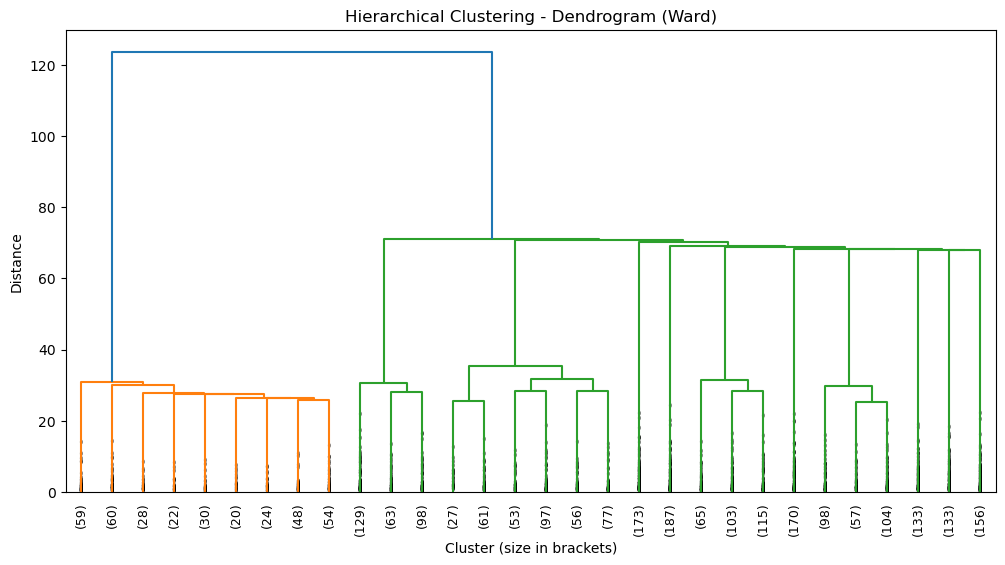

In [21]:
from scipy.cluster.hierarchy import linkage, dendrogram

# Linkage matrix (same ward method as AgglomerativeClustering)
Z = linkage(X_sample, method='ward')

plt.figure(figsize=(12, 6))

dendrogram(
    Z,
    truncate_mode='lastp',   # show only the last p merged clusters
    p=30,
    leaf_rotation=90,
    leaf_font_size=9,
    show_contracted=True
)

plt.title("Hierarchical Clustering - Dendrogram (Ward)")
plt.xlabel("Cluster (size in brackets)")
plt.ylabel("Distance")
plt.show()

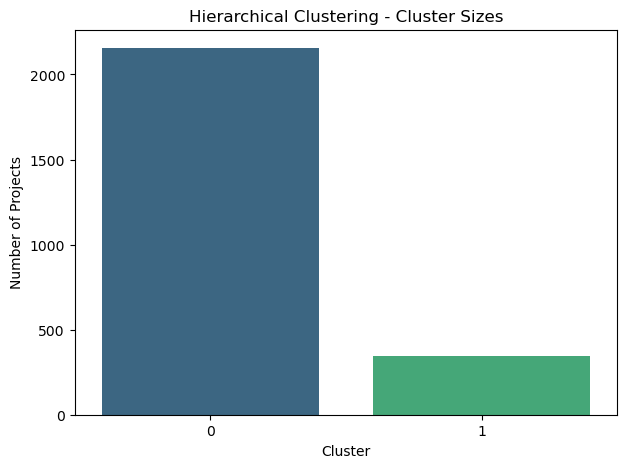

In [22]:
plt.figure(figsize=(7, 5))

sns.countplot(x=hierarchical_labels, palette='viridis')

plt.xlabel("Cluster")
plt.ylabel("Number of Projects")
plt.title("Hierarchical Clustering - Cluster Sizes")
plt.show()